# Training Without Clean Images

Alex Matteson

GitHub Link: https://github.com/AlexanderMatteson/Project2_ee513_Matteson 


In [5]:
# imports:
import rawpy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import cv2

### Part 1: A clean image from your burst

1. Load the sixteen frames of one burst and take the same green sites from each. Use your noisiest burst.
Deliverable: The number of frames, and the height and width of one half-size image.

In [2]:
# white level measured for out sensor:
filename = r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\Overexposed\RawCam-2026-11-16-135817.dng"

with rawpy.imread(filename) as raw:

    # Extract original Bayer mosaic
    bayer = raw.raw_image_visible.copy()

    # Sensor bit depth and black/white levels
    print("Raw image dimensions:", bayer.shape)
    print("Bit depth:", raw.color_desc)
    print("Black level:", raw.black_level_per_channel)
    print("White level:", raw.white_level)

    # Pixel statistics
    print("Minimum pixel value:", np.min(bayer))
    print("Maximum pixel value:", np.max(bayer))
    print("Mean pixel value:", np.mean(bayer))

    # Count pixels at maximum value
    print("Pixels at white level:",
          np.sum(bayer >= raw.white_level))

    print("Percentage saturated:",
          100 * np.mean(bayer >= raw.white_level))

Raw image dimensions: (3024, 4032)
Bit depth: b'RGBG'
Black level: [528, 528, 528, 528]
White level: 4095
Minimum pixel value: 545
Maximum pixel value: 4095
Mean pixel value: 1244.4173570759322
Pixels at white level: 295243
Percentage saturated: 2.4214599998950197


In [3]:
black = 528
white = 4095

# --------------------------------------------------
# Settings
# --------------------------------------------------

folder = Path(
    r"C:\Users\mattesoa\Documents\Project2_ee513_Matteson\AvgImages"
)

BLACK_LEVEL = black
SATURATION_LEVEL = white

GREEN_ROW = 0
GREEN_COL = 1

# --------------------------------------------------
# Load burst
# --------------------------------------------------

files = sorted(folder.glob("*.dng"))

if len(files) == 0:
    raise FileNotFoundError(f"No DNG files found in {folder}")

frames = []

for filename in files:

    with rawpy.imread(str(filename)) as raw:

        mosaic = raw.raw_image_visible.copy()

        # Extract one set of green Bayer sites
        green = mosaic[GREEN_ROW::2, GREEN_COL::2]

        # Normalize
        green = (
            green.astype(np.float32) - BLACK_LEVEL
        ) / (SATURATION_LEVEL - BLACK_LEVEL)

        green = np.clip(green, 0, 1)

        frames.append(green)

# Convert list into 3D NumPy array
frames = np.stack(frames, axis=0)

# --------------------------------------------------
# Report information
# --------------------------------------------------

num_frames, height, width = frames.shape

print("--- Burst Information ---")
print(f"Number of frames: {num_frames}")
print(f"Image height: {height}")
print(f"Image width: {width}")
print(f"Array dimensions: {frames.shape}")

print("\n--- Pixel Statistics ---")
print(f"Minimum: {frames.min():.6f}")
print(f"Maximum: {frames.max():.6f}")
print(f"Mean: {frames.mean():.6f}")


--- Burst Information ---
Number of frames: 16
Image height: 1512
Image width: 2016
Array dimensions: (16, 1512, 2016)

--- Pixel Statistics ---
Minimum: 0.000000
Maximum: 1.000000
Mean: 0.147574


2. Align every frame to the first. cv2.phaseCorrelate on a Hann-windowed pair gives the shift to a fraction of a pixel. cv2.warpAffine shifts it back. Report the median and the largest shift.
Deliverable: Those two numbers, in pixels.

In [6]:
# --------------------------------------------------
# Image registration
# --------------------------------------------------

# Reference image: first frame in burst
reference = frames[0]

# Create Hann window
hann = cv2.createHanningWindow(
    (width, height),
    cv2.CV_32F
)

registered_frames = np.zeros_like(frames)

# First frame is the reference
registered_frames[0] = reference

# Store estimated shifts
shifts = []

for i in range(1, num_frames):

    moving = frames[i]

    # Estimate translation relative to reference
    shift, response = cv2.phaseCorrelate(
        reference,
        moving,
        hann
    )

    dx, dy = shift

    shifts.append((dx, dy))

    # Apply inverse translation to align moving image
    M = np.array([
        [1, 0, -dx],
        [0, 1, -dy]
    ], dtype=np.float32)

    aligned = cv2.warpAffine(
        moving,
        M,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    registered_frames[i] = aligned

# --------------------------------------------------
# Calculate registration statistics
# --------------------------------------------------

shifts = np.array(shifts)

# Magnitude of each translation
shift_magnitudes = np.sqrt(
    shifts[:, 0]**2 + shifts[:, 1]**2
)

median_shift = np.median(shift_magnitudes)
max_shift = np.max(shift_magnitudes)

print("\n--- Registration Results ---")
print(f"Median shift: {median_shift:.4f} pixels")
print(f"Largest shift: {max_shift:.4f} pixels")

print("\nIndividual frame shifts (dx, dy):")
for i, (dx, dy) in enumerate(shifts, start=1):
    print(f"Frame {i+1}: ({dx:.4f}, {dy:.4f})")

# --------------------------------------------------
# Results are stored in memory
# --------------------------------------------------

# Original burst: frames
# Registered burst: registered_frames



--- Registration Results ---
Median shift: 2.8096 pixels
Largest shift: 8.4213 pixels

Individual frame shifts (dx, dy):
Frame 2: (-0.9316, 0.1869)
Frame 3: (-1.7334, 0.3562)
Frame 4: (-0.8723, 0.3768)
Frame 5: (-1.3951, 0.3641)
Frame 6: (0.0781, 0.3494)
Frame 7: (-2.7768, 0.4281)
Frame 8: (-1.5293, 0.4448)
Frame 9: (-0.8289, 0.4016)
Frame 10: (6.0958, 0.2634)
Frame 11: (7.7537, 0.5815)
Frame 12: (8.4166, 0.2801)
Frame 13: (7.0584, 0.2018)
Frame 14: (6.0583, 0.2704)
Frame 15: (5.0558, 0.0938)
Frame 16: (4.3409, 0.5433)


Question: the registration step warpaffine uses interpolation. Does this effect the noise or image in a way that would be an issue?

3. Average the aligned frames. That's your clean image. Show one frame and the average side by side, same crop, full scale, somewhere with fine detail.
Deliverable: One figure.

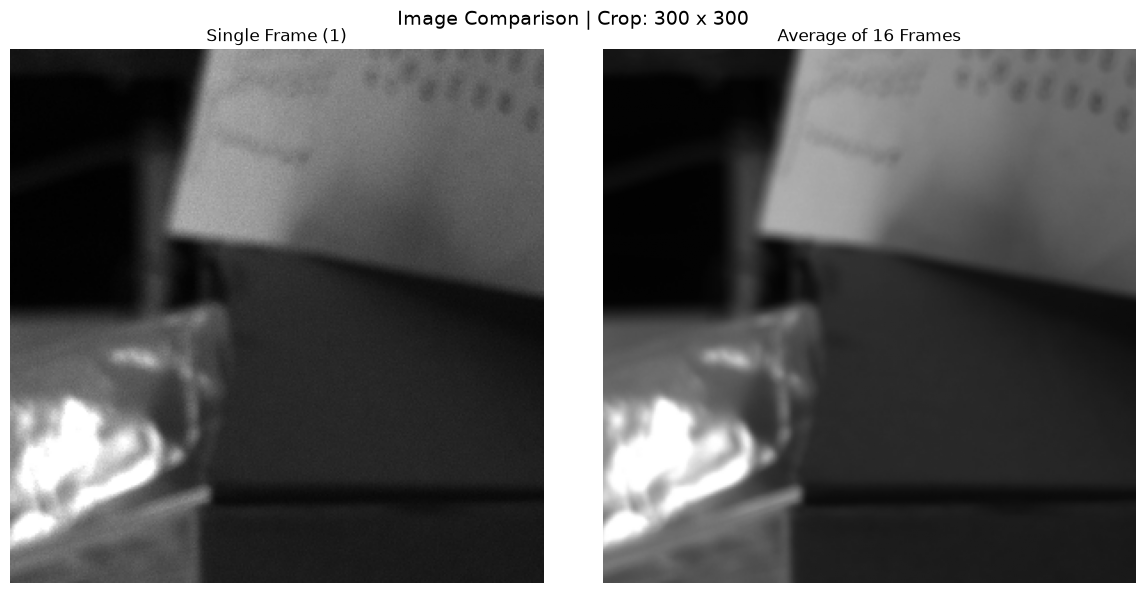

--- Averaging and Crop Information ---
Number of averaged frames: 16
Full image dimensions: 1512 x 2016
Crop dimensions: 300 x 300
Crop Y indices: 606:906
Crop X indices: 858:1158


In [7]:
# --------------------------------------------------
# 1. Average registered frames
# --------------------------------------------------

# Pixel-wise average across all frames
averaged_frame = np.mean(registered_frames, axis=0)

# Select one individual frame for comparison
# Change this index if desired (0 = first frame)
noisy_frame_index = 0
noisy_frame = registered_frames[noisy_frame_index]

# --------------------------------------------------
# 2. Define crop region
# --------------------------------------------------

height, width = averaged_frame.shape

# Crop dimensions (editable)
crop_height = 300
crop_width = 300

# Crop center (default: center of image)
center_y = height // 2
center_x = width // 2

# Crop boundaries
y_start = center_y - crop_height // 2
y_end = y_start + crop_height

x_start = center_x - crop_width // 2
x_end = x_start + crop_width

# Check crop boundaries
if (y_start < 0 or x_start < 0 or
    y_end > height or x_end > width):
    raise ValueError("Crop extends outside image boundaries.")

# Extract identical crop from both images
noisy_crop = noisy_frame[y_start:y_end, x_start:x_end]
average_crop = averaged_frame[y_start:y_end, x_start:x_end]

# --------------------------------------------------
# 3. Display side by side
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Same full intensity scale for both images
vmin = 0
vmax = 1

im1 = axes[0].imshow(
    noisy_crop,
    cmap='gray',
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title(f"Single Frame ({noisy_frame_index + 1})")
axes[0].axis('off')

im2 = axes[1].imshow(
    average_crop,
    cmap='gray',
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title(f"Average of {len(registered_frames)} Frames")
axes[1].axis('off')

plt.suptitle(
    f"Image Comparison | Crop: {crop_width} x {crop_height}",
    fontsize=14
)

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 4. Print crop and image information
# --------------------------------------------------

print("--- Averaging and Crop Information ---")
print(f"Number of averaged frames: {len(registered_frames)}")
print(f"Full image dimensions: {height} x {width}")
print(f"Crop dimensions: {crop_height} x {crop_width}")
print(f"Crop Y indices: {y_start}:{y_end}")
print(f"Crop X indices: {x_start}:{x_end}")


4. Estimate the noise in one frame from the difference of two aligned frames, divided by the square root of two. Do it twice. Once as a standard deviation, and once as the median absolute deviation divided by 0.6745. The 0.6745 makes the second estimate match the first when the data really is Gaussian. On my burst they came out a factor of two and a half apart.

Noise estimates from two aligned frames
----------------------------------------
Standard deviation estimate: 0.010465
MAD-based estimate:          0.005520
Ratio (std / MAD):           1.896


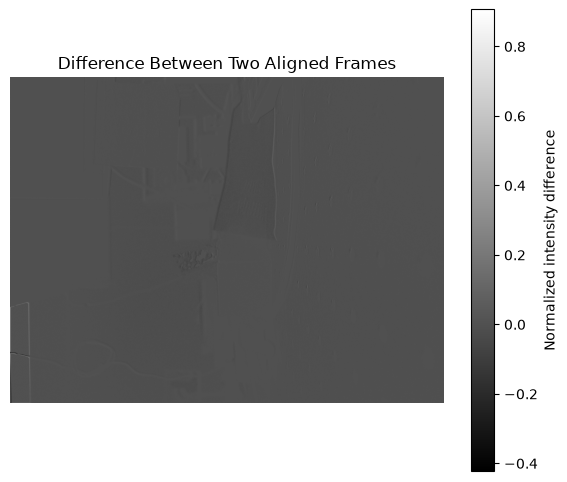

In [8]:
import numpy as np

# Select two aligned frames
frame1 = registered_frames[0].astype(np.float64)
frame2 = registered_frames[1].astype(np.float64)

# Difference image (common scene content should cancel)
difference = frame1 - frame2

# 1. Standard deviation estimate
# Difference noise is sqrt(2) times the noise in one frame
noise_std = np.std(difference, ddof=1) / np.sqrt(2)

# 2. Median absolute deviation estimate
# MAD is scaled by 0.6745 to estimate standard deviation for Gaussian data
difference_median = np.median(difference)
mad = np.median(np.abs(difference - difference_median))

noise_mad = mad / (0.6745 * np.sqrt(2))

# Print results
print("Noise estimates from two aligned frames")
print("----------------------------------------")
print(f"Standard deviation estimate: {noise_std:.6f}")
print(f"MAD-based estimate:          {noise_mad:.6f}")
print(f"Ratio (std / MAD):           {noise_std / noise_mad:.3f}")

# Display difference image

plt.figure(figsize=(7, 6))
plt.imshow(difference, cmap='gray')
plt.colorbar(label="Normalized intensity difference")
plt.title("Difference Between Two Aligned Frames")
plt.axis("off")
plt.show()

I believe that the difference tells us that the alignment is not perfect because the difference betweent the two frames is not just noise but also some signal component.

5. Build your training pair. Add two independent draws of Gaussian noise to your clean image, both at four times the robust estimate from item 4. Four times is two stops less shutter. That's sixteen times fewer photons. Report the PSNR of one noisy copy against the clean image, and say what peak you used.
Deliverable: The PSNR and the peak.

Robust noise estimate:       0.005520
Synthetic noise std (4x):    0.022080

Training pair results
---------------------
Noise standard deviation: 0.022080
MSE:                      0.00048794
Peak used for PSNR:       1.0
PSNR:                     33.12 dB


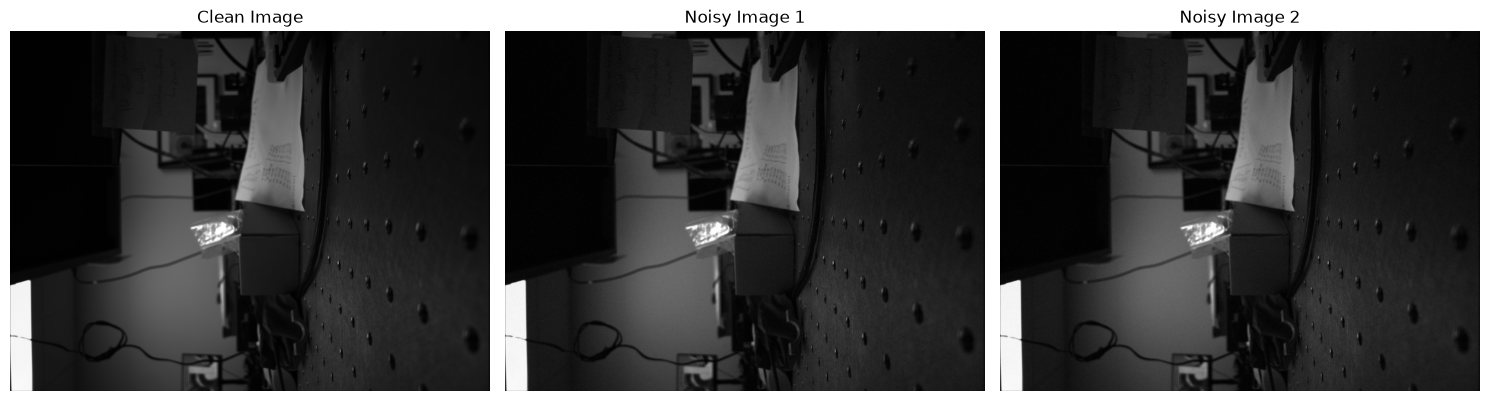

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define clean image
clean_image = averaged_frame.copy().astype(np.float32)

# 2. Define noise level
robust_noise_estimate = 0.005520
synthetic_noise_std = 4 * robust_noise_estimate

print(f"Robust noise estimate:       {robust_noise_estimate:.6f}")
print(f"Synthetic noise std (4x):    {synthetic_noise_std:.6f}")

# 3. Generate two independent Gaussian noise arrays
np.random.seed(42)  # Reproducibility

noise1 = np.random.normal(0, synthetic_noise_std, clean_image.shape)
noise2 = np.random.normal(0, synthetic_noise_std, clean_image.shape)

# 4. Create the two noisy images
noisy_image1 = clean_image + noise1
noisy_image2 = clean_image + noise2

# 5. Calculate PSNR of noisy image 1 against clean image
peak = 1.0

mse = np.mean((clean_image - noisy_image1) ** 2)
psnr = 10 * np.log10((peak ** 2) / mse)

# 6. Report results
print("\nTraining pair results")
print("---------------------")
print(f"Noise standard deviation: {synthetic_noise_std:.6f}")
print(f"MSE:                      {mse:.8f}")
print(f"Peak used for PSNR:       {peak:.1f}")
print(f"PSNR:                     {psnr:.2f} dB")

# 7. Display clean image and noisy copies
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [clean_image, noisy_image1, noisy_image2]
titles = ["Clean Image", "Noisy Image 1", "Noisy Image 2"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

### Part 2: Two ways to train

6. Define the network and report how many parameters it has.
Deliverable: The parameter count.

In [10]:
import torch
import torch.nn as nn

# Define the denoising CNN
class DenoisingCNN(nn.Module):
    def __init__(self):
        super(DenoisingCNN, self).__init__()

        self.network = nn.Sequential(
            # Layer 1: 1 input channel -> 32 output channels
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Layer 2: 32 -> 32 channels
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Layer 3: 32 -> 32 channels
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Layer 4: 32 -> 32 channels
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Layer 5: 32 -> 32 channels
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # Layer 6: 32 -> 1 channel (predicted noise)
            nn.Conv2d(32, 1, kernel_size=3, padding=1)
        )

    def forward(self, x):
        predicted_noise = self.network(x)
        denoised_image = x - predicted_noise
        return denoised_image, predicted_noise


# Initialize a fresh model
model = DenoisingCNN()

# Count trainable parameters
parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print("Denoising CNN")
print("-----------------------------")
print(f"Trainable parameters: {parameter_count:,}")

# Verify the expected parameter count
assert parameter_count == 37601, (
    f"Expected 37,601 parameters, got {parameter_count:,}"
)

print("Parameter count verified!")

# Test the network with a sample 64 x 64 image patch
test_input = torch.randn(1, 1, 64, 64)

denoised_output, predicted_noise = model(test_input)

print("\nTest output dimensions:")
print(f"Input:            {test_input.shape}")
print(f"Predicted noise:  {predicted_noise.shape}")
print(f"Denoised output:  {denoised_output.shape}")

Denoising CNN
-----------------------------
Trainable parameters: 37,601
Parameter count verified!

Test output dimensions:
Input:            torch.Size([1, 1, 64, 64])
Predicted noise:  torch.Size([1, 1, 64, 64])
Denoised output:  torch.Size([1, 1, 64, 64])


37601 total parameters.

7. Train it the ordinary way. Input the first noisy copy, target the clean image. Plot the loss against step.
Deliverable: One loss curve

Image dimensions: 1512 x 2016
Training region:  1512 x 1411
Step  100/800, Loss: 0.00009071
Step  200/800, Loss: 0.00003842
Step  300/800, Loss: 0.00002614
Step  400/800, Loss: 0.00003104
Step  500/800, Loss: 0.00002254
Step  600/800, Loss: 0.00003778
Step  700/800, Loss: 0.00002150
Step  800/800, Loss: 0.00001821


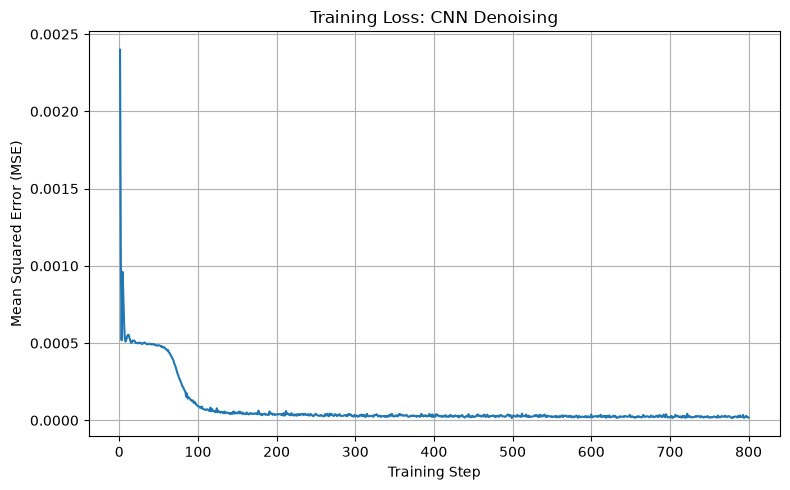

In [11]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Convert images to PyTorch tensors
# Shape must be (batch, channels, height, width)
clean_tensor = torch.from_numpy(
    clean_image.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

noisy_tensor = torch.from_numpy(
    noisy_image1.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

# 2. Define training region: left 70% of image
height, width = clean_image.shape
split_x = int(width * 0.70)

print(f"Image dimensions: {height} x {width}")
print(f"Training region:  {height} x {split_x}")

# 3. Initialize a fresh model
model = DenoisingCNN()

# 4. Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 5. Training settings
patch_size = 64
batch_size = 16
num_steps = 800

loss_history = []

# 6. Training loop
model.train()

for step in range(num_steps):

    # Randomly sample 16 patches from the left 70%
    y = torch.randint(0, height - patch_size + 1, (batch_size,))
    x = torch.randint(0, split_x - patch_size + 1, (batch_size,))

    noisy_patches = torch.stack([
        noisy_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    clean_patches = torch.stack([
        clean_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    # Forward pass
    denoised_patches, predicted_noise = model(noisy_patches)

    # Calculate loss against clean target
    loss = criterion(denoised_patches, clean_patches)

    # Backpropagation and parameter update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (step + 1) % 100 == 0:
        print(f"Step {step+1:4d}/{num_steps}, Loss: {loss.item():.8f}")

# 7. Plot loss against training step
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_steps + 1), loss_history)
plt.xlabel("Training Step")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training Loss: CNN Denoising")
plt.grid(True)
plt.tight_layout()
plt.show()

We have to pick a loss function; for this I picked the MSE. I picked this because this is what I remeber from my past experiences with NNs. I guess there are other loss functions we could pick, I need to think more about why we would pick one over the other.

8. Train a second copy the Noise2Noise way. Same input, but target the second noisy copy. Change nothing else. Plot the loss against step.
Deliverable: One loss curve.

Image dimensions: 1512 x 2016
Training region:  1512 x 1411
Step  100/800, Loss: 0.00059421
Step  200/800, Loss: 0.00052743
Step  300/800, Loss: 0.00051216
Step  400/800, Loss: 0.00051409
Step  500/800, Loss: 0.00051133
Step  600/800, Loss: 0.00052611
Step  700/800, Loss: 0.00050683
Step  800/800, Loss: 0.00051167


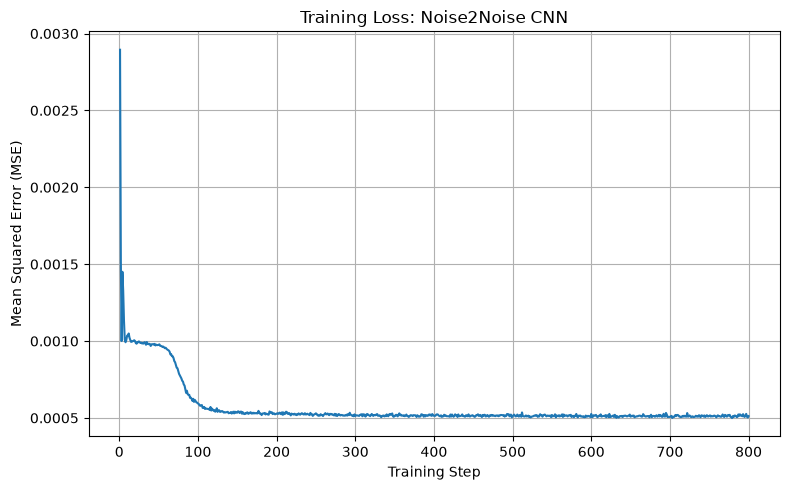

In [12]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# 1. Convert images to PyTorch tensors
noisy1_tensor = torch.from_numpy(
    noisy_image1.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

noisy2_tensor = torch.from_numpy(
    noisy_image2.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

# 2. Define training region: left 70% of image
height, width = clean_image.shape
split_x = int(width * 0.70)

print(f"Image dimensions: {height} x {width}")
print(f"Training region:  {height} x {split_x}")

# 3. Initialize a completely fresh model
model_n2n = DenoisingCNN()

# 4. Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model_n2n.parameters(), lr=0.001)

# 5. Training settings (unchanged)
patch_size = 64
batch_size = 16
num_steps = 800

loss_history_n2n = []

# 6. Training loop
model_n2n.train()

for step in range(num_steps):

    # Randomly sample 16 patch locations from the left 70%
    y = torch.randint(0, height - patch_size + 1, (batch_size,))
    x = torch.randint(0, split_x - patch_size + 1, (batch_size,))

    # Extract matching patches from both noisy images
    input_patches = torch.stack([
        noisy1_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    target_patches = torch.stack([
        noisy2_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    # Forward pass
    denoised_patches, predicted_noise = model_n2n(input_patches)

    # Calculate loss against the SECOND noisy image
    loss = criterion(denoised_patches, target_patches)

    # Backpropagation and parameter update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history_n2n.append(loss.item())

    if (step + 1) % 100 == 0:
        print(f"Step {step+1:4d}/{num_steps}, Loss: {loss.item():.8f}")

# 7. Plot loss against training step
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_steps + 1), loss_history_n2n)
plt.xlabel("Training Step")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training Loss: Noise2Noise CNN")
plt.grid(True)
plt.tight_layout()
plt.show()

9. The two losses settle at different levels. Say why. Give the number the gap should equal, then check it.
Deliverable: One sentence, the predicted number, and the measured gap.

There will be a difference because the first method could in therory reach zero loss by perfectly predicting the clean image, but the second method has a noisy target and thus can not achieve zero loss even with perfect denoising. The expected difference: sigma^2=(0.022080)^2 = 0.0004875. By looking what the loss vs step pltos converge to we see that they end up ~ 0.00049 appart, in agreement with what we expect. 

10. Report PSNR against the clean image on the held-out right 30 percent, for the noisy input and for each of the two networks.
Deliverable: Three PSNR values.

Held-out PSNR Results (Right 30%)
---------------------------------
Noisy input:          33.11 dB
Ordinary network:     47.48 dB
Noise2Noise network:  47.08 dB
Peak used:            1.0


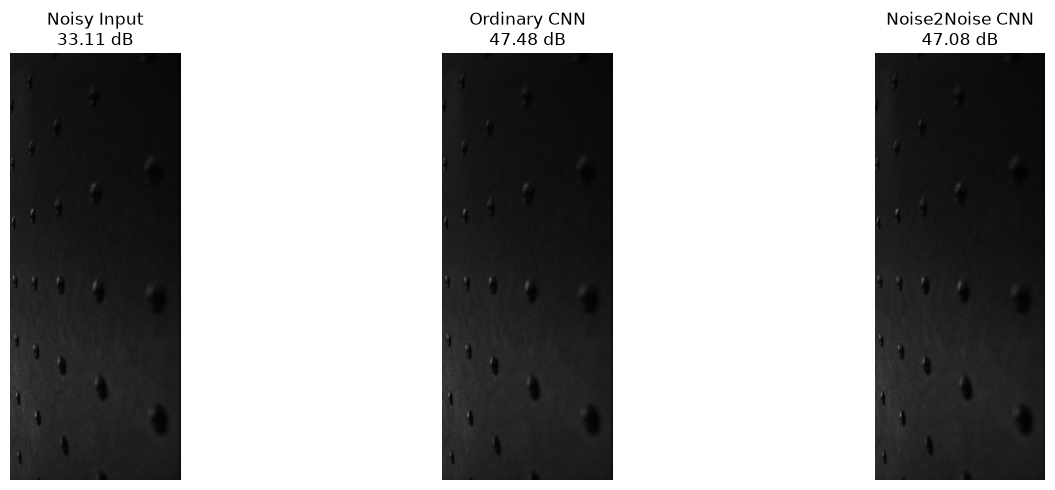

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# 1. Define held-out region (right 30% of image)
height, width = clean_image.shape
split_x = int(width * 0.70)

clean_test = clean_image[:, split_x:]
noisy_test = noisy_image1[:, split_x:]

# 2. Convert held-out noisy region to PyTorch tensor
noisy_test_tensor = torch.from_numpy(
    noisy_test.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

# 3. Generate denoised outputs
model.eval()
model_n2n.eval()

with torch.no_grad():
    # Ordinary network
    denoised_ordinary, _ = model(noisy_test_tensor)

    # Noise2Noise network
    denoised_n2n, _ = model_n2n(noisy_test_tensor)

# Convert outputs back to NumPy arrays
denoised_ordinary = denoised_ordinary.squeeze().cpu().numpy()
denoised_n2n = denoised_n2n.squeeze().cpu().numpy()

# 4. Calculate PSNR
def calculate_psnr(reference, test, peak=1.0):
    mse = np.mean((reference - test) ** 2)
    return 10 * np.log10((peak ** 2) / mse)

peak = 1.0

psnr_noisy = calculate_psnr(clean_test, noisy_test, peak)
psnr_ordinary = calculate_psnr(clean_test, denoised_ordinary, peak)
psnr_n2n = calculate_psnr(clean_test, denoised_n2n, peak)

# 5. Report results
print("Held-out PSNR Results (Right 30%)")
print("---------------------------------")
print(f"Noisy input:          {psnr_noisy:.2f} dB")
print(f"Ordinary network:     {psnr_ordinary:.2f} dB")
print(f"Noise2Noise network:  {psnr_n2n:.2f} dB")
print(f"Peak used:            {peak:.1f}")

# 6. Display comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    noisy_test,
    denoised_ordinary,
    denoised_n2n
]

titles = [
    f"Noisy Input\n{psnr_noisy:.2f} dB",
    f"Ordinary CNN\n{psnr_ordinary:.2f} dB",
    f"Noise2Noise CNN\n{psnr_n2n:.2f} dB"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

Despite the loss ending in different places the two methods seems to both perform similarly (as measured with PSNR). But also visulaly I do not think we can see much of an improvement (or much noise, for that matter).

### Part 3: Checking the number

11. Train the Noise2Noise network again from a different random seed. Change nothing else. Score it the same way, then compare the gap between the two seeds with the gap you found in item 10.
Deliverable: The second score, and one sentence on which difference is larger and what that lets you claim.

Image dimensions: 1512 x 2016
Training region:  1512 x 1411
Step  100/800, Loss: 0.00058747
Step  200/800, Loss: 0.00053016
Step  300/800, Loss: 0.00051197
Step  400/800, Loss: 0.00052019
Step  500/800, Loss: 0.00051415
Step  600/800, Loss: 0.00051102
Step  700/800, Loss: 0.00052307
Step  800/800, Loss: 0.00051630


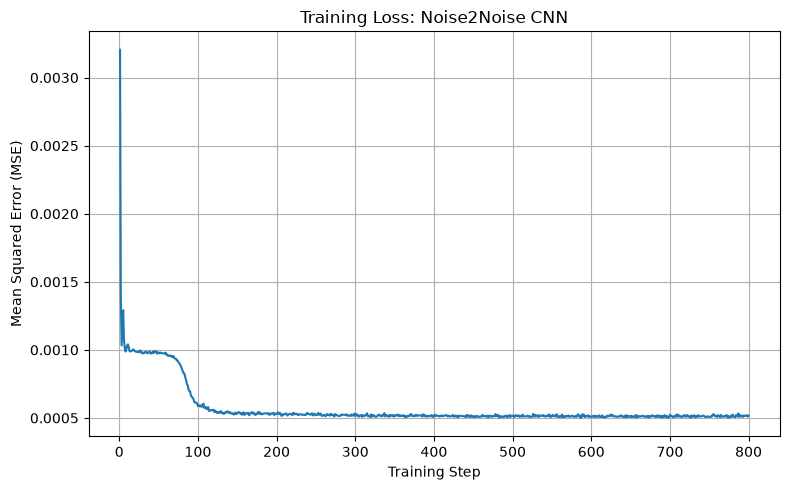

In [16]:

# Reproducibility
torch.manual_seed(51)
np.random.seed(10)

# 1. Convert images to PyTorch tensors
noisy1_tensor = torch.from_numpy(
    noisy_image1.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

noisy2_tensor = torch.from_numpy(
    noisy_image2.astype(np.float32)
).unsqueeze(0).unsqueeze(0)

# 2. Define training region: left 70% of image
height, width = clean_image.shape
split_x = int(width * 0.70)

print(f"Image dimensions: {height} x {width}")
print(f"Training region:  {height} x {split_x}")

# 3. Initialize a completely fresh model
model_n2n = DenoisingCNN()

# 4. Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model_n2n.parameters(), lr=0.001)

# 5. Training settings (unchanged)
patch_size = 64
batch_size = 16
num_steps = 800

loss_history_n2n = []

# 6. Training loop
model_n2n.train()

for step in range(num_steps):

    # Randomly sample 16 patch locations from the left 70%
    y = torch.randint(0, height - patch_size + 1, (batch_size,))
    x = torch.randint(0, split_x - patch_size + 1, (batch_size,))

    # Extract matching patches from both noisy images
    input_patches = torch.stack([
        noisy1_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    target_patches = torch.stack([
        noisy2_tensor[0, 0, y[i]:y[i]+patch_size, x[i]:x[i]+patch_size]
        for i in range(batch_size)
    ]).unsqueeze(1)

    # Forward pass
    denoised_patches, predicted_noise = model_n2n(input_patches)

    # Calculate loss against the SECOND noisy image
    loss = criterion(denoised_patches, target_patches)

    # Backpropagation and parameter update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    loss_history_n2n.append(loss.item())

    if (step + 1) % 100 == 0:
        print(f"Step {step+1:4d}/{num_steps}, Loss: {loss.item():.8f}")

# 7. Plot loss against training step
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_steps + 1), loss_history_n2n)
plt.xlabel("Training Step")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("Training Loss: Noise2Noise CNN")
plt.grid(True)
plt.tight_layout()
plt.show()

When I changed the random seed and got 0.00051167 both times, I think this shows our training is pretty stable even with different random patches and different random noise. When I changed the oytorch manual seed (i think this sets the inital weights selection) I got a training loss of 0.00051630. This is very similar but slightly different, maybe with slightly different initialization of the weights the gradient descent ends up in a slightly different place. But I think it is a good sign that with both changes to seeds we end up in a similar place.

12. Score the Noise2Noise network on eight random 128 by 128 crops of the held-out region. Then score it on five fresh noise draws of one fixed crop. Report a mean and a standard deviation for each.
Deliverable: Two mean-and-spread values. 

In [18]:
import numpy as np
import torch

# --------------------------------------------------
# Settings
# --------------------------------------------------

patch_size = 128
num_random_crops = 8
num_noise_draws = 5

robust_noise_estimate = 0.005520
synthetic_noise_std = 4 * robust_noise_estimate
peak = 1.0

# Reproducible crop locations and fresh noise draws
rng = np.random.default_rng(42)

# --------------------------------------------------
# 1. Define held-out region (right 30%)
# --------------------------------------------------

height, width = clean_image.shape
split_x = int(width * 0.70)

clean_test = clean_image[:, split_x:]
noisy_test = noisy_image1[:, split_x:]

test_height, test_width = clean_test.shape

if test_height < patch_size or test_width < patch_size:
    raise ValueError(
        f"Held-out region is only {test_height} x {test_width}. "
        f"It must be at least {patch_size} x {patch_size}."
    )

print(f"Held-out region: {test_height} x {test_width}")
print(f"Synthetic noise standard deviation: {synthetic_noise_std:.6f}")


# --------------------------------------------------
# 2. Define PSNR function
# --------------------------------------------------

def calculate_psnr(reference, test, peak=1.0):
    mse = np.mean((reference - test) ** 2)
    return 10 * np.log10((peak ** 2) / mse)


# --------------------------------------------------
# 3. Prepare Noise2Noise model
# --------------------------------------------------

device = next(model_n2n.parameters()).device

model_n2n.eval()

def denoise_patch(noisy_patch):
    """Run one 128 x 128 patch through the trained network."""

    patch_tensor = torch.from_numpy(
        noisy_patch.astype(np.float32)
    ).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        denoised, _ = model_n2n(patch_tensor)

    return denoised.squeeze().cpu().numpy()


# --------------------------------------------------
# EXPERIMENT A:
# Eight random 128 x 128 crops from held-out region
# --------------------------------------------------

psnr_random_crops = []

for i in range(num_random_crops):

    # Random crop location within held-out region
    y = rng.integers(0, test_height - patch_size + 1)
    x = rng.integers(0, test_width - patch_size + 1)

    # Extract corresponding clean and noisy patches
    clean_patch = clean_test[y:y+patch_size, x:x+patch_size]
    noisy_patch = noisy_test[y:y+patch_size, x:x+patch_size]

    # Denoise
    denoised_patch = denoise_patch(noisy_patch)

    # Calculate PSNR
    psnr = calculate_psnr(clean_patch, denoised_patch, peak)
    psnr_random_crops.append(psnr)

psnr_random_crops = np.array(psnr_random_crops)

mean_random = np.mean(psnr_random_crops)
std_random = np.std(psnr_random_crops, ddof=1)


# --------------------------------------------------
# EXPERIMENT B:
# Five fresh noise draws of one fixed 128 x 128 crop
# --------------------------------------------------

# Choose one fixed crop near the center of held-out region
fixed_y = (test_height - patch_size) // 2
fixed_x = (test_width - patch_size) // 2

fixed_clean_patch = clean_test[
    fixed_y:fixed_y+patch_size,
    fixed_x:fixed_x+patch_size
]

psnr_fresh_noise = []

for i in range(num_noise_draws):

    # Generate a fresh, independent Gaussian noise realization
    fresh_noise = rng.normal(
        loc=0,
        scale=synthetic_noise_std,
        size=fixed_clean_patch.shape
    )

    # Add noise to the same clean crop
    fresh_noisy_patch = fixed_clean_patch + fresh_noise

    # Denoise
    denoised_patch = denoise_patch(fresh_noisy_patch)

    # Calculate PSNR against the fixed clean crop
    psnr = calculate_psnr(
        fixed_clean_patch,
        denoised_patch,
        peak
    )

    psnr_fresh_noise.append(psnr)

psnr_fresh_noise = np.array(psnr_fresh_noise)

mean_fresh = np.mean(psnr_fresh_noise)
std_fresh = np.std(psnr_fresh_noise, ddof=1)


# --------------------------------------------------
# 4. Report results
# --------------------------------------------------

print("\n============================================")
print("EXPERIMENT A: Eight random held-out crops")
print("============================================")

for i, value in enumerate(psnr_random_crops):
    print(f"Crop {i+1}: {value:.2f} dB")

print(f"\nMean PSNR: {mean_random:.2f} dB")
print(f"Std PSNR:  {std_random:.2f} dB")
print(f"Result:    {mean_random:.2f} +/- {std_random:.2f} dB")


print("\n============================================")
print("EXPERIMENT B: Five fresh noise realizations")
print("============================================")

for i, value in enumerate(psnr_fresh_noise):
    print(f"Noise draw {i+1}: {value:.2f} dB")

print(f"\nMean PSNR: {mean_fresh:.2f} dB")
print(f"Std PSNR:  {std_fresh:.2f} dB")
print(f"Result:    {mean_fresh:.2f} +/- {std_fresh:.2f} dB")

Held-out region: 1512 x 605
Synthetic noise standard deviation: 0.022080

EXPERIMENT A: Eight random held-out crops
Crop 1: 49.75 dB
Crop 2: 47.95 dB
Crop 3: 49.19 dB
Crop 4: 49.25 dB
Crop 5: 47.58 dB
Crop 6: 49.33 dB
Crop 7: 48.55 dB
Crop 8: 48.57 dB

Mean PSNR: 48.77 dB
Std PSNR:  0.74 dB
Result:    48.77 +/- 0.74 dB

EXPERIMENT B: Five fresh noise realizations
Noise draw 1: 48.54 dB
Noise draw 2: 48.49 dB
Noise draw 3: 48.76 dB
Noise draw 4: 48.43 dB
Noise draw 5: 48.53 dB

Mean PSNR: 48.55 dB
Std PSNR:  0.13 dB
Result:    48.55 +/- 0.13 dB


13. One of those spreads is much larger. Say which, and what that means if you report a single PSNR from a single crop.
Deliverable: Two sentences.

The first spread is larger, I think this means that while we are robust to different random noises the spatial variability does not generalize as well. This would mean that we if we report a single PSNR from one crop we are not capturing the full story, we may perform better or worse on another crop and therefor we need to do multiple crops to have a better understanding of how our model works on average (and what the variability is).

14. Make a correlated noise field. Smooth Gaussian noise with a 1-pixel Gaussian, then rescale it to the standard deviation you trained at. Add it to the clean image and run the same network. Report the PSNR going in and coming out.
Deliverable: Two PSNR values.

In [19]:
from scipy.ndimage import gaussian_filter

# --------------------------------------------------
# 1. Set noise parameters
# --------------------------------------------------

robust_noise_estimate = 0.005520
synthetic_noise_std = 4 * robust_noise_estimate  # 0.022080
peak = 1.0

rng = np.random.default_rng(42)

# --------------------------------------------------
# 2. Generate and smooth Gaussian noise
# --------------------------------------------------

# Generate independent standard Gaussian noise
noise = rng.normal(0, 1, size=clean_image.shape).astype(np.float32)

# Smooth with a Gaussian having sigma = 1 pixel
correlated_noise = gaussian_filter(noise, sigma=1).astype(np.float32)

# --------------------------------------------------
# 3. Rescale to the training noise standard deviation
# --------------------------------------------------

# Center the noise and rescale its standard deviation
correlated_noise -= np.mean(correlated_noise)
correlated_noise *= synthetic_noise_std / np.std(correlated_noise)

print(f"Target noise std:       {synthetic_noise_std:.6f}")
print(f"Correlated noise std:   {np.std(correlated_noise):.6f}")

# --------------------------------------------------
# 4. Add correlated noise to the clean image
# --------------------------------------------------

# Do not clip: preserve the Gaussian noise distribution
noisy_correlated = clean_image.astype(np.float32) + correlated_noise

# --------------------------------------------------
# 5. Calculate input PSNR
# --------------------------------------------------

def calculate_psnr(reference, test, peak=1.0):
    mse = np.mean((reference - test) ** 2)
    return 10 * np.log10((peak ** 2) / mse)

psnr_input = calculate_psnr(clean_image, noisy_correlated, peak)

# --------------------------------------------------
# 6. Run the Noise2Noise network
# --------------------------------------------------

device = next(model_n2n.parameters()).device
model_n2n.eval()

input_tensor = torch.from_numpy(noisy_correlated).float()
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0).to(device)

with torch.no_grad():
    denoised_tensor, predicted_noise = model_n2n(input_tensor)

denoised_correlated = denoised_tensor.squeeze().cpu().numpy()

# --------------------------------------------------
# 7. Calculate output PSNR
# --------------------------------------------------

psnr_output = calculate_psnr(clean_image, denoised_correlated, peak)

print("\n--- Correlated Noise Results ---")
print(f"Input PSNR:   {psnr_input:.2f} dB")
print(f"Output PSNR:  {psnr_output:.2f} dB")
print(f"PSNR improvement: {psnr_output - psnr_input:.2f} dB")


Target noise std:       0.022080
Correlated noise std:   0.022080

--- Correlated Noise Results ---
Input PSNR:   33.12 dB
Output PSNR:  38.10 dB
PSNR improvement: 4.98 dB


The starting PSNR input is similar as before. The output and improvement is less, I guess this makes sense as the model is not trained on correlated noise but on random noise, this would amtter because the real noise model would be correlated.

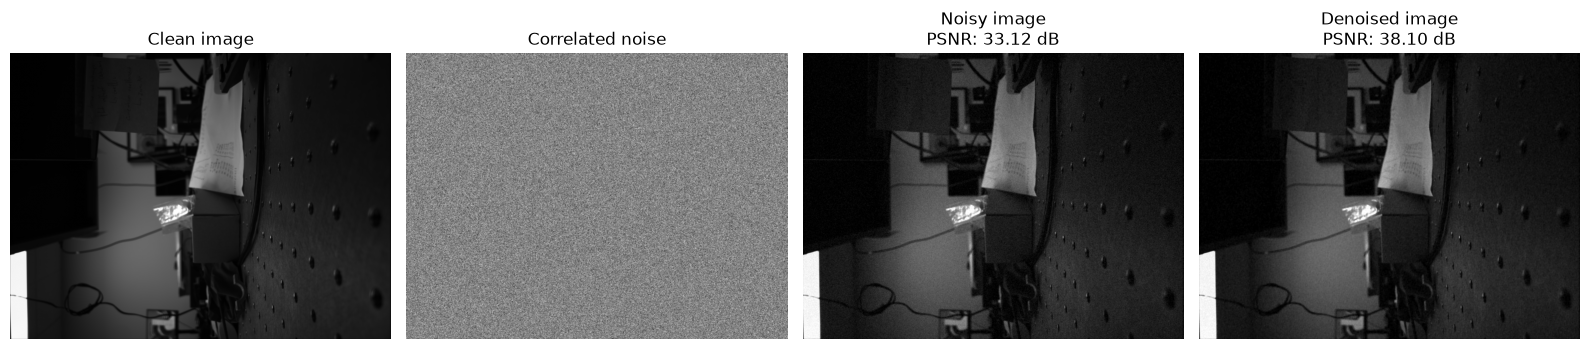

In [20]:
# Lets looks at the noise images (check everything is looking good)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(clean_image, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Clean image")

axes[1].imshow(correlated_noise, cmap='gray')
axes[1].set_title("Correlated noise")

axes[2].imshow(noisy_correlated, cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f"Noisy image\nPSNR: {psnr_input:.2f} dB")

axes[3].imshow(denoised_correlated, cmap='gray', vmin=0, vmax=1)
axes[3].set_title(f"Denoised image\nPSNR: {psnr_output:.2f} dB")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


15. Run the network on one real raw frame from your burst. Score it against the same clean image. It'll do much less than item 10 suggests.
Deliverable: The PSNR in and out, and two sentences on the two separate reasons it does worse.

Frame selected: 0
PSNR in:  37.82 dB
PSNR out: 38.90 dB
Improvement: +1.09 dB


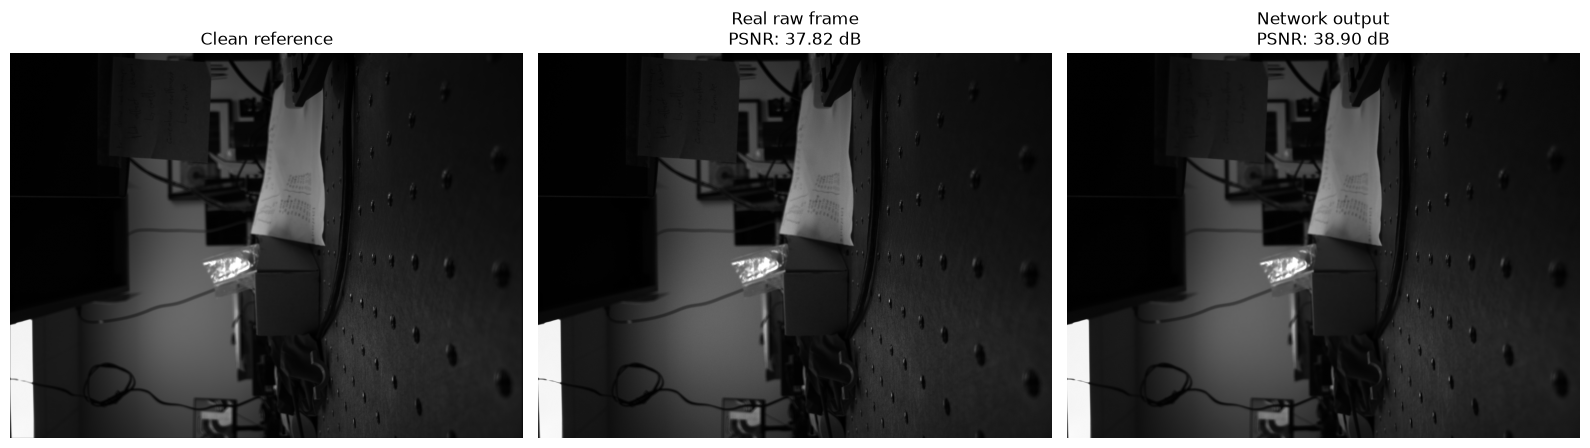

In [21]:
# --------------------------------------------------
# 1. Select one real registered frame
# --------------------------------------------------

# Select a frame from the burst.
# Change this index if you want to test a different frame.
frame_index = 0

real_noisy_frame = registered_frames[frame_index].astype(np.float32)

# Reference image
clean = clean_image.astype(np.float32)

# Check dimensions
assert real_noisy_frame.shape == clean.shape, (
    f"Shape mismatch: frame {real_noisy_frame.shape}, "
    f"clean image {clean.shape}"
)

# --------------------------------------------------
# 2. Calculate input PSNR
# --------------------------------------------------

psnr_in = calculate_psnr(clean, real_noisy_frame, peak=1.0)

# --------------------------------------------------
# 3. Run the Noise2Noise network
# --------------------------------------------------

device = next(model_n2n.parameters()).device

# Convert image to PyTorch format: (N, C, H, W)
input_tensor = torch.from_numpy(real_noisy_frame).float()
input_tensor = input_tensor.unsqueeze(0).unsqueeze(0).to(device)

model_n2n.eval()

with torch.no_grad():
    denoised_tensor, predicted_noise = model_n2n(input_tensor)

denoised_image = denoised_tensor.squeeze().cpu().numpy()

# --------------------------------------------------
# 4. Calculate output PSNR
# --------------------------------------------------

psnr_out = calculate_psnr(clean, denoised_image, peak=1.0)

# --------------------------------------------------
# 5. Report results
# --------------------------------------------------

print(f"Frame selected: {frame_index}")
print(f"PSNR in:  {psnr_in:.2f} dB")
print(f"PSNR out: {psnr_out:.2f} dB")
print(f"Improvement: {psnr_out - psnr_in:+.2f} dB")

# --------------------------------------------------
# 6. Visualize results
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(clean, cmap='gray', vmin=0, vmax=1)
axes[0].set_title("Clean reference")

axes[1].imshow(real_noisy_frame, cmap='gray', vmin=0, vmax=1)
axes[1].set_title(f"Real raw frame\nPSNR: {psnr_in:.2f} dB")

axes[2].imshow(denoised_image, cmap='gray', vmin=0, vmax=1)
axes[2].set_title(f"Network output\nPSNR: {psnr_out:.2f} dB")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()


One reason I can think of is that the training for this model learned the random Gaussian noise that we added for training and therefor does not generalize well to the real images where noise may not (probably not) structured like that. A second reason besides the shape of the additive gaussian noise could be the size of the noise, maybe indevidual frames have a higher or lower noise level but he model was only trained on one noise level so it does not generalize well to this new nosie level.

### Part 4: ONNX and runtime

This is the export you'll need for Project 2 Part C, on a smaller network. Export with dynamo=True. Mark height and width free, so the file works at any image size.

16. Export the Noise2Noise network to ONNX and load it with onnxruntime. Run the same input through it and through PyTorch. Report the largest absolute difference.

In [22]:

import numpy as np
import torch
import onnx
import onnxruntime as ort

# --------------------------------------------------
# 1. Prepare the input
# --------------------------------------------------

# Use the same real raw frame from the previous step
# Shape: (1, 1, height, width)

device = next(model_n2n.parameters()).device

input_tensor = torch.from_numpy(
    real_noisy_frame.astype(np.float32)
).unsqueeze(0).unsqueeze(0).to(device)

model_n2n.eval()

# --------------------------------------------------
# 2. Define dynamic height and width
# --------------------------------------------------

height_dim = torch.export.Dim("height", min=1)
width_dim = torch.export.Dim("width", min=1)

dynamic_shapes = {
    "x": {
        2: height_dim,
        3: width_dim
    }
}

# --------------------------------------------------
# 3. Export the PyTorch model to ONNX
# --------------------------------------------------

onnx_path = "noise2noise.onnx"

torch.onnx.export(
    model_n2n,
    (input_tensor,),
    onnx_path,
    input_names=["noisy_image"],
    output_names=["denoised_image", "predicted_noise"],
    dynamo=True,
    dynamic_shapes=dynamic_shapes
)

print(f"ONNX model exported to: {onnx_path}")

# --------------------------------------------------
# 4. Check the exported ONNX model
# --------------------------------------------------

onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

print("ONNX model passed validation.")

# --------------------------------------------------
# 5. Load the ONNX model using ONNX Runtime
# --------------------------------------------------

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# --------------------------------------------------
# 6. Run the same input through PyTorch
# --------------------------------------------------

with torch.no_grad():
    pytorch_output, pytorch_noise = model_n2n(input_tensor)

pytorch_output = pytorch_output.cpu().numpy()

# --------------------------------------------------
# 7. Run the same input through ONNX Runtime
# --------------------------------------------------

input_numpy = input_tensor.detach().cpu().numpy()

onnx_output, onnx_noise = session.run(
    ["denoised_image", "predicted_noise"],
    {"noisy_image": input_numpy}
)

# --------------------------------------------------
# 8. Calculate maximum absolute difference
# --------------------------------------------------

absolute_difference = np.abs(pytorch_output - onnx_output)

max_difference = np.max(absolute_difference)
mean_difference = np.mean(absolute_difference)

print("\n--- PyTorch vs ONNX Results ---")
print(f"Maximum absolute difference: {max_difference:.10f}")
print(f"Mean absolute difference:    {mean_difference:.10f}")


[torch.onnx] Obtain model graph for `DenoisingCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DenoisingCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX model exported to: noise2noise.onnx
ONNX model passed validation.

--- PyTorch vs ONNX Results ---
Maximum absolute difference: 0.0000001192
Mean absolute difference:    0.0000000125


Maybe we could campare it to differences in using different seeds. We should get similar reaults from the pytorch and ONNX with the differences being from like different initializarion? I'm defnitly not sure abour ONNX.

17. Time one forward pass at 512 by 512 through onnxruntime. Ten runs, after one warm-up run you throw away. Report the mean and the standard deviation. Say what hardware and what image size they belong to.
Deliverable: The timing with its spread, the size, and the hardware.

In [23]:
providers=["CPUExecutionProvider"]


import numpy as np
import onnxruntime as ort
import time
import platform
import os

# --------------------------------------------------
# 1. Load ONNX model
# --------------------------------------------------

onnx_path = "noise2noise.onnx"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# --------------------------------------------------
# 2. Prepare a 512 x 512 input
# --------------------------------------------------

image_size = 512

height, width = real_noisy_frame.shape

if height < image_size or width < image_size:
    raise ValueError(
        f"Image is {height} x {width}; "
        f"it must be at least {image_size} x {image_size}."
    )

# Extract center crop
y_start = (height - image_size) // 2
x_start = (width - image_size) // 2

input_image = real_noisy_frame[
    y_start:y_start + image_size,
    x_start:x_start + image_size
].astype(np.float32)

# ONNX input format: (batch, channels, height, width)
input_numpy = input_image[np.newaxis, np.newaxis, :, :]

print("Input shape:", input_numpy.shape)

# --------------------------------------------------
# 3. Warm-up run (not timed)
# --------------------------------------------------

_ = session.run(
    ["denoised_image"],
    {"noisy_image": input_numpy}
)

# --------------------------------------------------
# 4. Time ten forward passes
# --------------------------------------------------

num_runs = 10
times_ms = []

for i in range(num_runs):

    start_time = time.perf_counter()

    _ = session.run(
        ["denoised_image"],
        {"noisy_image": input_numpy}
    )

    end_time = time.perf_counter()

    elapsed_ms = (end_time - start_time) * 1000
    times_ms.append(elapsed_ms)

times_ms = np.array(times_ms)

# Mean and sample standard deviation
mean_time = np.mean(times_ms)
std_time = np.std(times_ms, ddof=1)

# --------------------------------------------------
# 5. Identify hardware
# --------------------------------------------------

cpu_name = platform.processor()

# Additional CPU identification on Linux
if not cpu_name and os.path.exists("/proc/cpuinfo"):
    with open("/proc/cpuinfo", "r") as f:
        for line in f:
            if "model name" in line:
                cpu_name = line.split(":", 1)[1].strip()
                break

if not cpu_name:
    cpu_name = platform.machine()

print("\n--- Hardware ---")
print("CPU:", cpu_name)
print("Logical CPU cores:", os.cpu_count())
print("Operating system:", platform.platform())
print("ONNX Runtime device:", ort.get_device())
print("Execution provider:", session.get_providers()[0])

# --------------------------------------------------
# 6. Report timing
# --------------------------------------------------

print("\n--- ONNX Runtime Benchmark ---")
print(f"Image size: {image_size} x {image_size}")
print(f"Number of timed runs: {num_runs}")
print(f"Warm-up runs discarded: 1")

print("\nIndividual timings (ms):")
print(np.round(times_ms, 3))

print(f"\nMean inference time: {mean_time:.3f} ms")
print(f"Standard deviation:  {std_time:.3f} ms")
print(f"Result: {mean_time:.3f} +/- {std_time:.3f} ms")


Input shape: (1, 1, 512, 512)

--- Hardware ---
CPU: Intel64 Family 6 Model 183 Stepping 1, GenuineIntel
Logical CPU cores: 28
Operating system: Windows-11-10.0.26200-SP0
ONNX Runtime device: CPU
Execution provider: CPUExecutionProvider

--- ONNX Runtime Benchmark ---
Image size: 512 x 512
Number of timed runs: 10
Warm-up runs discarded: 1

Individual timings (ms):
[68.282 67.967 68.322 63.6   56.902 54.79  60.844 59.73  58.401 61.034]

Mean inference time: 61.987 ms
Standard deviation:  4.898 ms
Result: 61.987 +/- 4.898 ms


### Reflections:

18. this assignment waws helpful for concretly illistrating how the way you construct teh training dataset influences how the model works and generalizes. For denoising htis means that the model learns the tyoe of synthetic noise you create which may not generalize well to actual nosie. This idea is broadly applicable for the creation of training datat for Cnns.

19. I have questiosn abiut what is ONNX? And what teh purpose of using it is? I guess I should probably look this up.

20. AI: I used chatgpt to help write the python scripts for this assignment. For this time I tried writing out for myself a structure of what I wanted to do for each step and then asked the model to fill inthe code. I think breaking it up this way made it easier to check because I can read over each part of each step. Reading over the code, and checking if the outputs make sense given the knowledge from the class were important when using AI code. Also, visually viewing images (nosie, de noised etc) and plots (loss) are good manual checks. I think having the two methods to train and checking that they are off by the expected amount is another good catch/verfication.